# The class becomes the dataset

**Question.** What does Class Mode reveal when the detectives become the data? We follow the game’s event log through pandas, statistics, and detective profiles.

In [1]:
import sys
sys.path.insert(0, "../backend")
sys.path.insert(0, "../backend/tests")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, chi2_contingency
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from auditor.autopsy import player_table
from auditor.profiles import assign_archetypes, FEATURES
from auditor.generator.cases import LEVELS
from auditor.tools.registry import TOOLS
from fixtures import synthetic_events
sns.set_theme(style="darkgrid", context="notebook", palette=["#F5A524", "#4CC9F0", "#E5484D", "#3DD68C"])
plt.rcParams.update({"figure.facecolor":"#0E1117", "axes.facecolor":"#161B24", "axes.labelcolor":"#E8E6E1", "text.color":"#E8E6E1", "xtick.color":"#E8E6E1", "ytick.color":"#E8E6E1", "grid.color":"#394252", "savefig.facecolor":"#0E1117"})
AMBER, CYAN, RED, GREEN = "#F5A524", "#4CC9F0", "#E5484D", "#3DD68C"

## 1. What telemetry does the game record?

**Question.** What is in a raw event, and what is inside its JSON payload? The SQLite logger decodes payload JSON into dictionaries on read.

In [2]:
events = synthetic_events(200, seed=0)
display(events.head())
display(events.type.value_counts().rename_axis("event_type").to_frame("count"))
flat = pd.concat([events.drop(columns="payload").reset_index(drop=True), pd.json_normalize(events.payload).add_prefix("payload.")], axis=1)
display(flat.head(10))

,ts,type,player_id,case_id,room_code,tool_id,payload
0,0.0,case_started,P000,C000,TEST,NaN,"{'level': 6, 'seed': 1}"
1,0.0,tool_run,P000,C000,TEST,groupby,"{'cost': 1, 'visual': True}"
2,0.0,tool_run,P000,C000,TEST,regression,"{'cost': 4, 'visual': True}"
3,0.0,accused,P000,C000,TEST,NaN,"{'correct': False, 'score': 0, 'elapsed_s': 29..."
4,1.0,case_started,P001,C001,TEST,NaN,"{'level': 6, 'seed': 1}"


,count
event_type,
tool_run,931
case_started,200
accused,189
hacker_query,80


,ts,type,player_id,case_id,room_code,tool_id,payload.level,payload.seed,payload.cost,payload.visual,payload.correct,payload.score,payload.elapsed_s,payload.budget_left
0,0.0,case_started,P000,C000,TEST,NaN,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0,tool_run,P000,C000,TEST,groupby,NaN,NaN,1.0,True,NaN,NaN,NaN,NaN
2,0.0,tool_run,P000,C000,TEST,regression,NaN,NaN,4.0,True,NaN,NaN,NaN,NaN
3,0.0,accused,P000,C000,TEST,NaN,6.0,NaN,NaN,NaN,False,0.0,295.0,9.0
4,1.0,case_started,P001,C001,TEST,NaN,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
5,1.0,tool_run,P001,C001,TEST,timeseries,NaN,NaN,3.0,True,NaN,NaN,NaN,NaN
6,1.0,tool_run,P001,C001,TEST,timeseries,NaN,NaN,3.0,True,NaN,NaN,NaN,NaN
7,1.0,tool_run,P001,C001,TEST,regression,NaN,NaN,4.0,True,NaN,NaN,NaN,NaN
8,1.0,accused,P001,C001,TEST,NaN,6.0,NaN,NaN,NaN,True,1600.0,372.0,4.0
9,2.0,case_started,P002,C002,TEST,NaN,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN


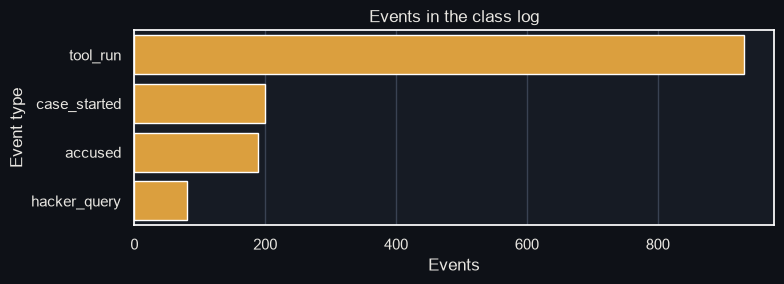

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.countplot(data=events, y="type", order=events.type.value_counts().index, color=AMBER, ax=ax)
ax.set(title="Events in the class log", xlabel="Events", ylabel="Event type")
plt.tight_layout(); plt.show()

**Takeaway.** One player produces several events. Flattened payload fields are missing where they do not apply to an event type.

## 2. Rebuild `player_table()`

**Question.** Can groupby and a pivot recover the game’s one-row-per-player table?

In [4]:
tools = events[events.type.eq("tool_run")].copy()
starts = events[events.type.eq("case_started")].drop_duplicates("player_id").set_index("player_id")
accused = events[events.type.eq("accused")].drop_duplicates("player_id", keep="first").set_index("player_id")
ids = pd.Index(sorted(events.player_id.dropna().unique()), name="player_id")
manual = pd.DataFrame(index=ids)
runs = pd.pivot_table(tools, index="player_id", columns="tool_id", values="type", aggfunc="count", fill_value=0)
manual["n_tools"] = runs.sum(axis=1)
manual["distinct_tools"] = runs.gt(0).sum(axis=1)
spent = tools.assign(cost=tools.payload.map(lambda p: p.get("cost", 0))).groupby("player_id").cost.sum()
budget = starts.payload.map(lambda p: LEVELS[p.get("level", 1)].budget)
manual["budget_spent_ratio"] = (spent / budget).round(3)
manual["seconds_to_accuse"] = accused.payload.map(lambda p: p.get("elapsed_s")).astype(float)
manual["correct"] = accused.payload.map(lambda p: int(bool(p.get("correct"))))
manual["visual_tool_share"] = tools.assign(visual=tools.payload.map(lambda p: p.get("visual", True))).groupby("player_id").visual.mean().round(3)
manual["hacker_queries"] = events[events.type.eq("hacker_query")].groupby("player_id").size()
manual["score"] = accused.payload.map(lambda p: p.get("score", 0))
manual = manual.fillna({col: 0 for col in manual if col != "seconds_to_accuse"})
for col in ("n_tools", "distinct_tools", "correct", "hacker_queries", "score"):
    manual[col] = manual[col].astype(int)
players = player_table(events)
pd.testing.assert_frame_equal(manual[players.columns], players)
print("Hand-built table equals player_table on all shared columns.")
display(players.head())

Hand-built table equals player_table on all shared columns.


,n_tools,distinct_tools,budget_spent_ratio,seconds_to_accuse,correct,visual_tool_share,hacker_queries,score
player_id,,,,,,,,
P000,2,2,0.556,295.0,0,1.000,0,0
P001,3,2,1.111,372.0,1,1.000,0,1600
P002,0,0,0.000,69.0,0,0.000,0,0
P003,14,8,3.778,526.0,1,0.929,0,3800
P004,1,1,0.111,73.0,0,0.000,0,0


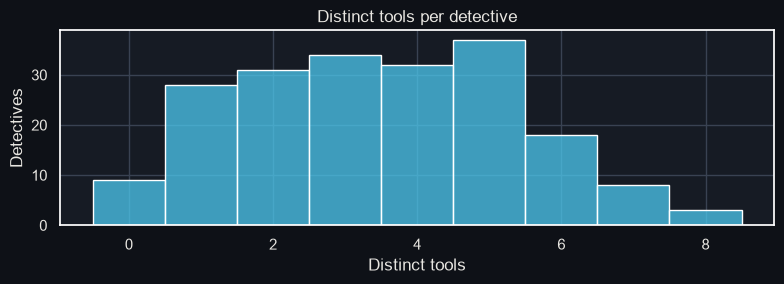

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(data=players, x="distinct_tools", discrete=True, color=CYAN, ax=ax)
ax.set(title="Distinct tools per detective", xlabel="Distinct tools", ylabel="Detectives")
plt.tight_layout(); plt.show()

**Takeaway.** Pivot row sums count runs; nonzero pivot columns count distinct tools. A missing accusation leaves time missing.

## 3. Descriptive statistics and distributions

**Question.** How do tool use and accusation time differ by outcome?

In [6]:
players = players.assign(outcome=np.where(players.correct.eq(1), "Correct", "Wrong or no accusation"))
display(players[["n_tools", "distinct_tools", "seconds_to_accuse", "correct", "score"]].describe().round(2))
print(f"Solve rate: {players.correct.mean():.1%}; median time: {players.seconds_to_accuse.median():.0f} seconds")
display(players.groupby("outcome")[["n_tools", "seconds_to_accuse"]].median())

,n_tools,distinct_tools,seconds_to_accuse,correct,score
count,200.00,200.00,189.00,200.00,200.00
mean,4.66,3.46,228.00,0.46,960.00
std,3.09,1.91,111.47,0.50,1131.37
min,0.00,0.00,63.00,0.00,0.00
25%,2.00,2.00,138.00,0.00,0.00
50%,4.00,3.00,225.00,0.00,0.00
75%,7.00,5.00,299.00,1.00,2000.00
max,15.00,8.00,526.00,1.00,4000.00


Solve rate: 45.5%; median time: 225 seconds


,n_tools,seconds_to_accuse
outcome,,
Correct,5.0,289.0
Wrong or no accusation,3.0,156.0


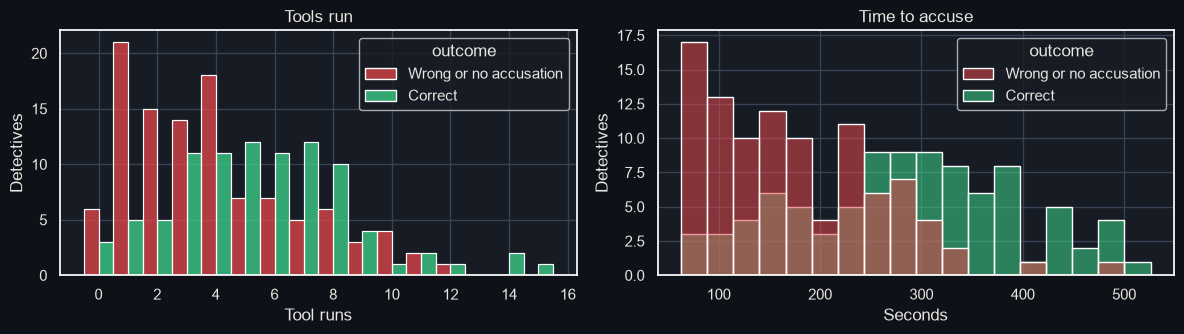

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
palette = {"Correct": GREEN, "Wrong or no accusation": RED}
sns.histplot(data=players, x="n_tools", hue="outcome", palette=palette, multiple="dodge", discrete=True, ax=axes[0])
sns.histplot(data=players.dropna(subset=["seconds_to_accuse"]), x="seconds_to_accuse", hue="outcome", palette=palette, bins=18, alpha=.55, ax=axes[1])
axes[0].set(title="Tools run", xlabel="Tool runs", ylabel="Detectives")
axes[1].set(title="Time to accuse", xlabel="Seconds", ylabel="Detectives")
plt.tight_layout(); plt.show()

**Takeaway.** The time plot includes only players who accused. Compare distributions, not only medians.

## 4. Does more analysis pay off?

**Question.** Is tool use associated with a correct accusation? Pearson r measures association; logistic regression draws a fitted probability curve.

In [8]:
r, p = pearsonr(players.n_tools, players.correct)
model = LogisticRegression(random_state=0).fit(players[["n_tools"]], players.correct)
grid = pd.DataFrame({"n_tools": np.linspace(players.n_tools.min(), players.n_tools.max(), 200)})
probability = model.predict_proba(grid)[:, 1]
print(f"Pearson r = {r:.3f}; p = {p:.3g}")
print(f"Logistic coefficient = {model.coef_[0,0]:.3f}; odds ratio per tool = {np.exp(model.coef_[0,0]):.3f}")

Pearson r = 0.265; p = 0.000146
Logistic coefficient = 0.184; odds ratio per tool = 1.201


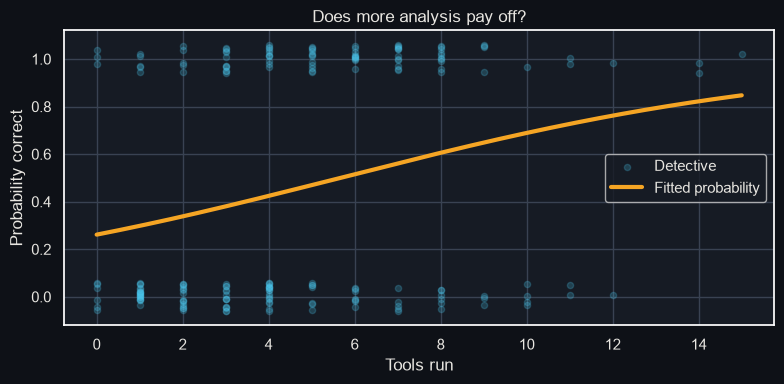

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
jitter = np.random.default_rng(0).uniform(-.06, .06, len(players))
ax.scatter(players.n_tools, players.correct + jitter, alpha=.22, s=20, color=CYAN, label="Detective")
ax.plot(grid.n_tools, probability, color=AMBER, lw=3, label="Fitted probability")
ax.set(title="Does more analysis pay off?", xlabel="Tools run", ylabel="Probability correct", ylim=(-.12, 1.12))
ax.legend(); plt.tight_layout(); plt.show()

**Takeaway.** A positive association does not prove that another tool causes success. The synthetic fixture makes detective skill affect both tool use and accuracy.

## 5. Which tool predicts success?

**Question.** Does the correct/wrong split differ for users and non-users of each tool? Each 2×2 table counts players, not runs.

In [10]:
rows = []
for tool_id in sorted(tools.tool_id.unique()):
    used = players.index.isin(tools.loc[tools.tool_id.eq(tool_id), "player_id"])
    users, others = players.loc[used, "correct"], players.loc[~used, "correct"]
    if not len(users) or not len(others): continue
    table = [[users.sum(), len(users)-users.sum()], [others.sum(), len(others)-others.sum()]]
    chi2, p_value, _, _ = chi2_contingency(table)
    rows.append({"tool": TOOLS[tool_id].name, "users": len(users), "user_success": users.mean(), "non_user_success": others.mean(), "chi2": chi2, "p_value": p_value})
results = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
display(results.round(4))

,tool,users,user_success,non_user_success,chi2,p_value
0,Case Summary,79,0.5570,0.3884,4.8159,0.0282
1,Pattern Matrix,73,0.5616,0.3937,4.6169,0.0317
2,Box & Whisker,80,0.5500,0.3917,4.2351,0.0396
3,Z-Score Scan,75,0.5467,0.4000,3.4963,0.0615
4,Margin Model,82,0.5366,0.3983,3.1938,0.0739
5,Twin Finder,77,0.5195,0.4146,1.6977,0.1926
6,Benford's Law,74,0.5135,0.4206,1.2689,0.2600
7,Timeline,77,0.4935,0.4309,0.5174,0.4719
8,Anomaly Hunter,76,0.4868,0.4355,0.3155,0.5743


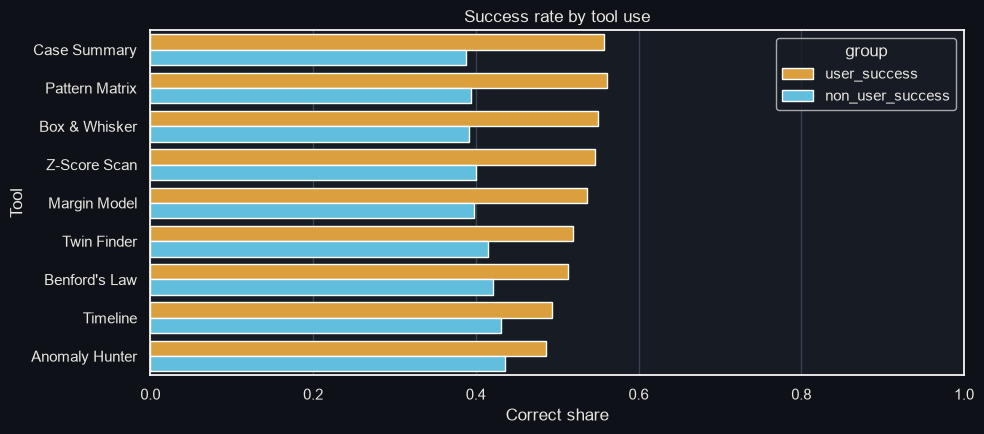

In [11]:
plot = results.melt(id_vars="tool", value_vars=["user_success", "non_user_success"], var_name="group", value_name="success_rate")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=plot, y="tool", x="success_rate", hue="group", order=results.tool, palette={"user_success": AMBER, "non_user_success": CYAN}, ax=ax)
ax.set(title="Success rate by tool use", xlabel="Correct share", ylabel="Tool", xlim=(0,1))
plt.tight_layout(); plt.show()

**Takeaway.** Smaller p-values indicate stronger evidence of association in this sample. Nine comparisons and skill-driven tool choice limit causal interpretation.

## 6. KMeans detective archetypes

**Question.** Why does the game use four archetypes? We standardize its seven profile features, compare k=2…8, and project production labels into two PCA dimensions.

In [12]:
X = players[FEATURES].copy()
X["seconds_to_accuse"] = X["seconds_to_accuse"].fillna(X["seconds_to_accuse"].max() or 0)
scaler = StandardScaler()
scaled = scaler.fit_transform(X)
ks = list(range(2, 9)); inertia = []; silhouette = []
for k in ks:
    fit = KMeans(n_clusters=k, n_init=10, random_state=0).fit(scaled)
    inertia.append(fit.inertia_)
    silhouette.append(silhouette_score(scaled, fit.labels_))
display(pd.DataFrame({"k":ks, "inertia":inertia, "silhouette":silhouette}).round(3))

,k,inertia,silhouette
0,2,931.333,0.307
1,3,755.702,0.323
2,4,637.802,0.319
3,5,495.779,0.344
4,6,431.123,0.335
5,7,381.611,0.343
6,8,336.764,0.367


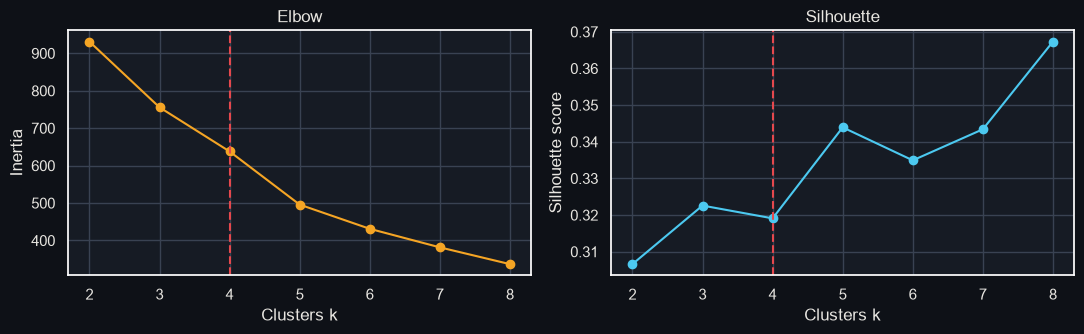

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, values, title, ylabel, color in zip(axes, [inertia,silhouette], ["Elbow", "Silhouette"], ["Inertia", "Silhouette score"], [AMBER,CYAN]):
    ax.plot(ks, values, marker="o", color=color)
    ax.axvline(4, color=RED, ls="--")
    ax.set(title=title, xlabel="Clusters k", ylabel=ylabel, xticks=ks)
plt.tight_layout(); plt.show()

**Takeaway.** Inertia always falls as k grows; silhouette measures separation. k=4 supports four named detective cards, and these diagnostics show its tradeoff rather than a uniquely correct k.

In [14]:
fit4 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(scaled)
labels = assign_archetypes(players)
centres = pd.DataFrame(scaler.inverse_transform(fit4.cluster_centers_), columns=FEATURES)
names = labels.groupby(pd.Series(fit4.labels_, index=players.index)).agg(lambda s: s.mode().iat[0])
centres.insert(0, "archetype", centres.index.map(names))
centres.insert(1, "players", np.bincount(fit4.labels_))
display(centres.set_index("archetype").round(2))
coords = PCA(n_components=2).fit_transform(scaled)
projected = pd.DataFrame({"PC1":coords[:,0], "PC2":coords[:,1], "archetype":labels.to_numpy()})

,players,n_tools,distinct_tools,budget_spent_ratio,seconds_to_accuse,correct,visual_tool_share,hacker_queries
archetype,,,,,,,,
The Visualizer,66,2.88,2.47,0.83,176.11,-0.00,0.97,0.05
The Statistician,72,7.92,5.40,2.29,343.29,0.64,0.87,0.11
The Hacker,46,3.43,2.83,0.97,225.89,0.91,0.89,1.41
The Gambler,16,0.81,0.69,0.13,134.19,0.19,0.10,0.25


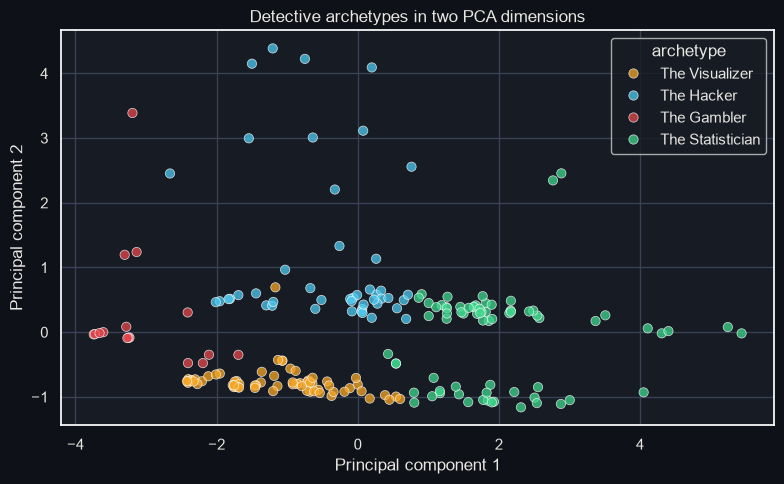

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=projected, x="PC1", y="PC2", hue="archetype", palette={"The Statistician": GREEN, "The Gambler": RED, "The Hacker": CYAN, "The Visualizer": AMBER}, alpha=.75, s=45, ax=ax)
ax.set(title="Detective archetypes in two PCA dimensions", xlabel="Principal component 1", ylabel="Principal component 2")
plt.tight_layout(); plt.show()

**Takeaway.** Cluster centres are shown in original units. PCA compresses seven features to two, so visible overlap need not mean overlap in the full feature space.

## 7. Conclusion

The class log becomes a reproducible dataset: events become player features, then distributions, associations, and profiles. Classroom data deserve the same caution about confounding, sample size, and multiple tests.